In [ ]:

from google.colab import files
import pandas as pd

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

display(df.head())


Saving placement_predict_50k Dataset.csv to placement_predict_50k Dataset (1).csv
Dataset loaded successfully!
Dataset shape: (50000, 32)
Column names: ['StudentID', 'Gender', 'City', 'CollegeTier', 'Stream', 'Specialisation', 'Hostel', 'HistoryOfBacklogs', 'SGPA_Sem1', 'SGPA_Sem2', 'SGPA_Sem3', 'SGPA_Sem4', 'SGPA_Sem5', 'SGPA_Sem6', 'SGPA_Sem7', 'SGPA_Sem8', 'CGPA', 'AttendancePercent', 'Internships', 'Projects', 'Workshops', 'Certifications', 'Publications', 'AptitudeTestScore', 'SoftSkillsRating', 'CodingTestScore', 'MockInterviewScore', 'ExtraCurricular', 'CGPA_Tier', 'PlacementStatus', 'IsAnomaly', 'Salary Package']


,StudentID,Gender,City,CollegeTier,Stream,Specialisation,Hostel,HistoryOfBacklogs,SGPA_Sem1,SGPA_Sem2,...,Publications,AptitudeTestScore,SoftSkillsRating,CodingTestScore,MockInterviewScore,ExtraCurricular,CGPA_Tier,PlacementStatus,IsAnomaly,Salary Package
0,1,Male,Ahmedabad,Tier2,ECE,Networking,No,No,6.02,6.54,...,0,66.7,2.2,49.4,47.8,0,Low,0,0,0.00
1,2,Female,Mumbai,Tier2,ECE,DataScience,Yes,Yes,5.84,5.12,...,0,48.2,2.4,26.7,25.8,0,Low,0,0,0.00
2,3,Male,Kolkata,Tier2,IT,DataScience,Yes,No,4.91,5.29,...,0,73.8,2.8,67.7,41.5,0,Low,1,0,3.89
3,4,Male,Jaipur,Tier1,CS,AI,No,No,7.67,8.03,...,0,69.8,2.7,66.9,48.0,0,Mid,1,0,8.37
4,5,Male,Pune,Tier2,IT,DataScience,Yes,No,8.14,8.97,...,1,73.1,2.1,71.7,61.7,1,High,1,0,18.99


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

X = df.drop(columns=["PlacementStatus", "CGPA_Tier"])
y = df["PlacementStatus"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

print("Dataset prepared successfully!")
print("Training samples:", X_train_processed.shape[0])
print("Validation samples:", X_val_processed.shape[0])


Dataset prepared successfully!
Training samples: 40000
Validation samples: 10000


In [ ]:

X = df.drop(columns=["PlacementStatus", "CGPA_Tier"])
y = df["PlacementStatus"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

feature_names = preprocessor.get_feature_names_out()

print("Preprocessing completed!")
print("Training samples:", X_train_processed.shape[0])
print("Validation samples:", X_val_processed.shape[0])


Preprocessing completed!
Training samples: 40000
Validation samples: 10000


In [ ]:

comparison = []

for criterion in ["gini", "entropy"]:
    model = DecisionTreeClassifier(
        criterion=criterion,
        random_state=42
    )

    model.fit(X_train_processed, y_train)

    comparison.append({
        "Criterion": criterion,
        "Train Accuracy": accuracy_score(
            y_train, model.predict(X_train_processed)
        ),
        "Validation Accuracy": accuracy_score(
            y_val, model.predict(X_val_processed)
        ),
        "Number of Leaves": model.get_n_leaves()
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df.round(4))


,Criterion,Train Accuracy,Validation Accuracy,Number of Leaves
0,gini,1.0,0.9963,74
1,entropy,1.0,0.9971,53


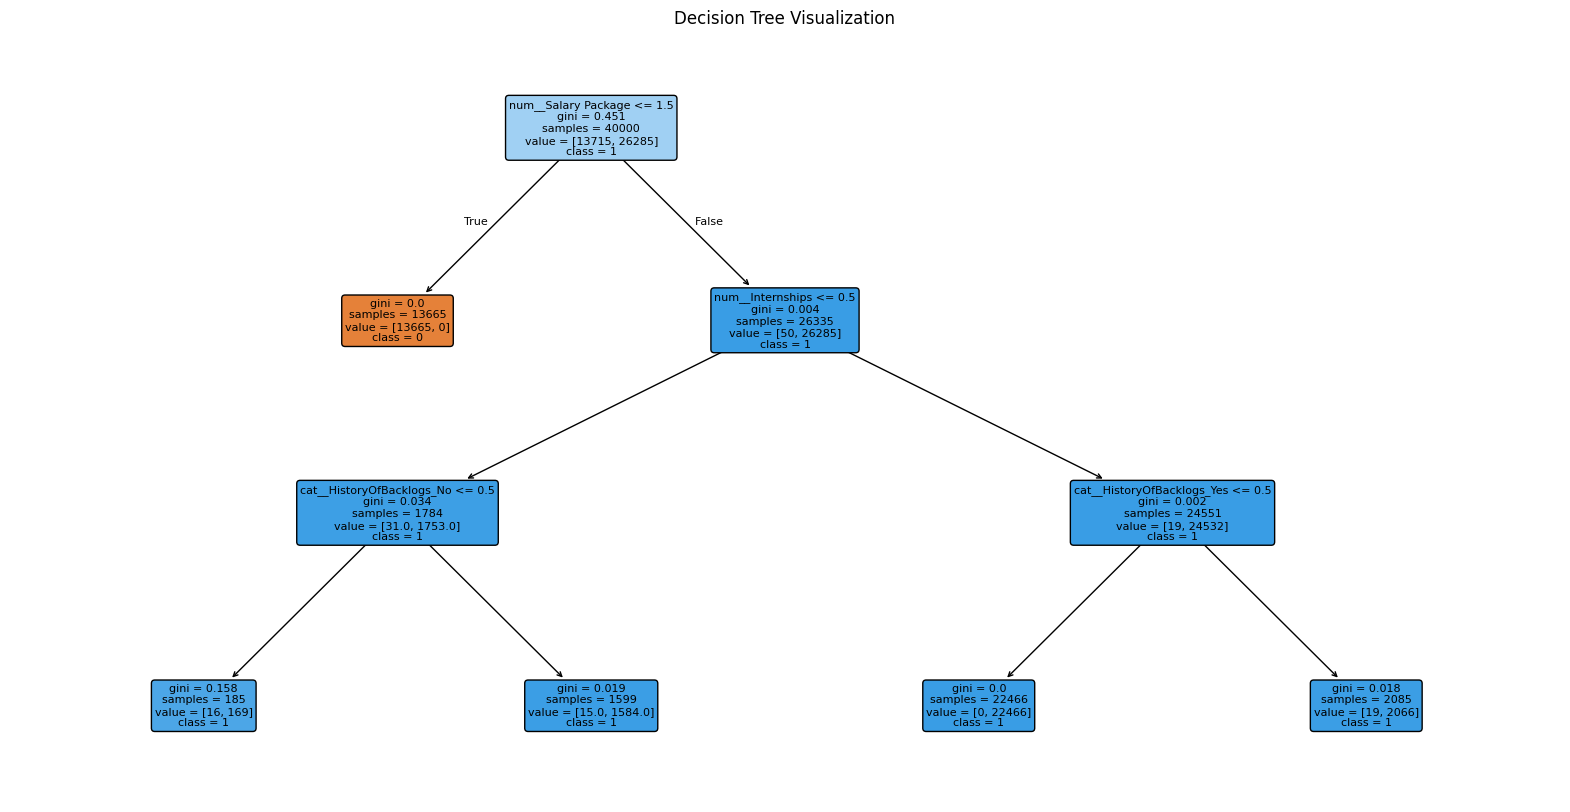

In [ ]:

tree_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

tree_model.fit(X_train_processed, y_train)

plt.figure(figsize=(20, 10))

plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=[str(c) for c in tree_model.classes_],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Visualization")
plt.show()


Number of pruning alpha values: 19
First 10 alpha values: [0.00000000e+00 1.66170635e-05 2.42063492e-05 2.44094488e-05
 2.44186047e-05 2.48380130e-05 3.14007318e-05 3.22794974e-05
 3.33333333e-05 3.44246668e-05]


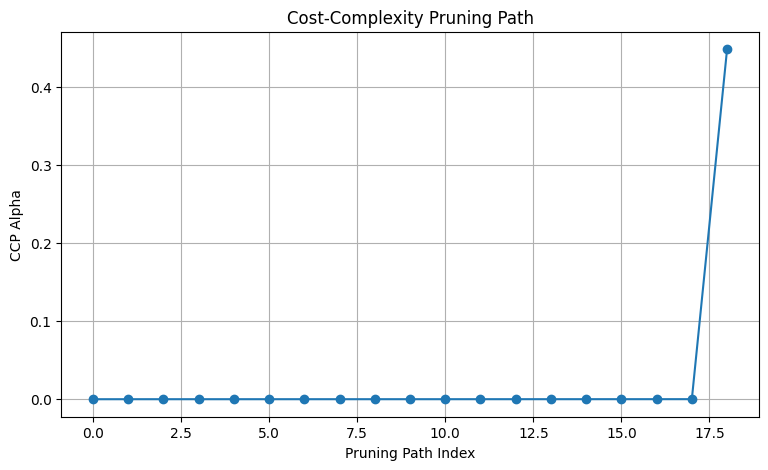

In [ ]:

base_tree = DecisionTreeClassifier(random_state=42)
base_tree.fit(X_train_processed, y_train)

path = base_tree.cost_complexity_pruning_path(
    X_train_processed, y_train
)

ccp_alphas = path.ccp_alphas

print("Number of pruning alpha values:", len(ccp_alphas))
print("First 10 alpha values:", ccp_alphas[:10])

plt.figure(figsize=(9, 5))
plt.plot(range(len(ccp_alphas)), ccp_alphas, marker="o")
plt.xlabel("Pruning Path Index")
plt.ylabel("CCP Alpha")
plt.title("Cost-Complexity Pruning Path")
plt.grid(True)
plt.show()


In [ ]:

def dt_report(X_train, y_train, X_val, y_val):
    results = []

    for depth in range(1, 16):
        model = DecisionTreeClassifier(
            max_depth=depth,
            random_state=42
        )

        model.fit(X_train, y_train)

        train_acc = accuracy_score(
            y_train, model.predict(X_train)
        )

        val_acc = accuracy_score(
            y_val, model.predict(X_val)
        )

        results.append({
            "depth": depth,
            "train_acc": train_acc,
            "val_acc": val_acc,
            "n_leaves": model.get_n_leaves()
        })

    report_df = pd.DataFrame(results)

    plt.figure(figsize=(10, 5))
    plt.plot(
        report_df["depth"], report_df["train_acc"],
        marker="o", label="Training Accuracy"
    )
    plt.plot(
        report_df["depth"], report_df["val_acc"],
        marker="s", label="Validation Accuracy"
    )

    plt.xlabel("Maximum Depth")
    plt.ylabel("Accuracy")
    plt.title("Decision Tree Depth Sweep")
    plt.xticks(range(1, 16))
    plt.legend()
    plt.grid(True)
    plt.show()

    best_row = report_df.loc[report_df["val_acc"].idxmax()]

    print("Best result based on validation accuracy:")
    print(best_row)

    return report_df


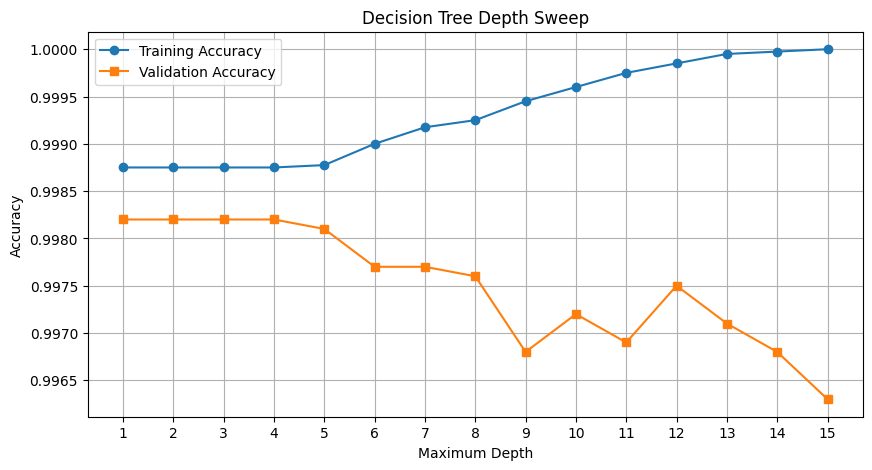

Best result based on validation accuracy:
depth        1.00000
train_acc    0.99875
val_acc      0.99820
n_leaves     2.00000
Name: 0, dtype: float64


,depth,train_acc,val_acc,n_leaves
0,1,0.9988,0.9982,2
1,2,0.9988,0.9982,3
2,3,0.9988,0.9982,5
3,4,0.9988,0.9982,8
4,5,0.9988,0.9981,13
5,6,0.9990,0.9977,20
6,7,0.9992,0.9977,25
7,8,0.9992,0.9976,32
8,9,0.9994,0.9968,41
9,10,0.9996,0.9972,50


In [ ]:

dt_results = dt_report(
    X_train_processed,
    y_train,
    X_val_processed,
    y_val
)

display(dt_results.round(4))


,ccp_alpha,train_acc,val_acc,n_leaves
0,0.0000,1.0000,0.9963,74
1,0.0000,0.9999,0.9964,64
2,0.0000,0.9998,0.9964,56
3,0.0000,0.9996,0.9972,42
4,0.0000,0.9994,0.9975,30
5,0.0000,0.9991,0.9979,16
6,0.0000,0.9991,0.9979,14
7,0.0000,0.9990,0.9979,12
8,0.0001,0.9988,0.9978,7
9,0.4481,0.6571,0.6571,1


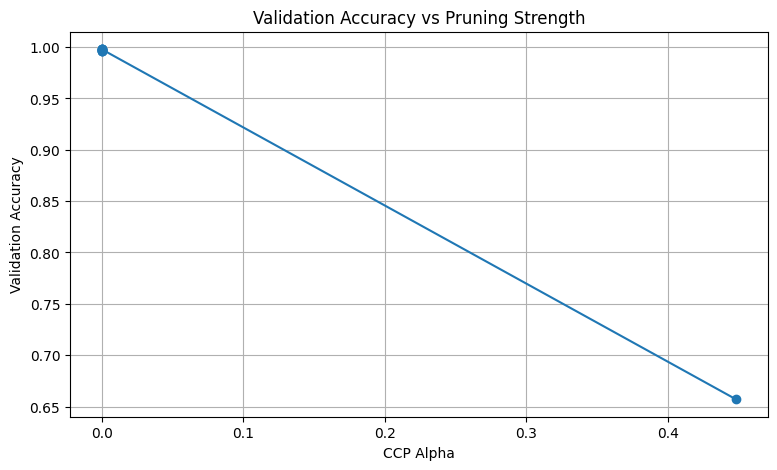

In [ ]:

selected_alphas = np.unique(
    np.quantile(
        ccp_alphas,
        np.linspace(0, 1, min(10, len(ccp_alphas)))
    )
)

pruning_results = []

for alpha in selected_alphas:
    model = DecisionTreeClassifier(
        ccp_alpha=float(alpha),
        random_state=42
    )

    model.fit(X_train_processed, y_train)

    pruning_results.append({
        "ccp_alpha": alpha,
        "train_acc": accuracy_score(
            y_train, model.predict(X_train_processed)
        ),
        "val_acc": accuracy_score(
            y_val, model.predict(X_val_processed)
        ),
        "n_leaves": model.get_n_leaves()
    })

pruning_df = pd.DataFrame(pruning_results)
display(pruning_df.round(4))

plt.figure(figsize=(9, 5))
plt.plot(
    pruning_df["ccp_alpha"],
    pruning_df["val_acc"],
    marker="o"
)
plt.xlabel("CCP Alpha")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy vs Pruning Strength")
plt.grid(True)
plt.show()


In [ ]:

best_pruned = pruning_df.loc[pruning_df["val_acc"].idxmax()]

print("Best pruning result:")
print(best_pruned)

print("\nDecision Tree practical completed successfully!")


Best pruning result:
ccp_alpha     0.000037
train_acc     0.999125
val_acc       0.997900
n_leaves     16.000000
Name: 5, dtype: float64

Decision Tree practical completed successfully!
